# Лабораторная работа № 1. Регрессия и метод главных компонент

## Введение

### Цель работы
Изучение основ линейной регрессии, построение простейших моделей регрессии, проведение обучения модели на реальных данных и оценка её качество.

### Задачи
1. Загрузить датасет из репозитория (например, kaggle.com или аналогичных платформ).
2. Подготовить данные: провести первичный анализ, визуализировать распределение признаков и целевой переменной.
3. Провести предобработку данных: удалить пропущенные значения, закодировать категориальные переменные (опционально).
4. Построить матрицу корреляций. Сделать выводы о наличии мультиколлинеарности (расчет VIF-коэффициента).
5. Построить регрессионные модели (линейная, лассо и гребневая). Если целевая переменная - категориальная, то исследовать логистическую регрессию. Разделить на тренировочную и тестовую выборки (80/20 или 70/30). Использовать кросс-валидацию. Оценить качество построенной модели с помощью метрик: RMSE (Root Mean Square Error), R² (коэффициент детерминации) и MAPE (Mean Absolute Percentage Error)..
6. Построить график остатков моделей (добавить горизонтальную линию на уровне 0) и исследовать структуру остатков на предмет гомоскедастичности или гетероскедастичности.
7. Устранить мультиколлинеарность и снизить размерность признаков с помощью метода главных компонент (PCA). Перед проведением PCA провести стандартизацию данных.
8. Повторить шаг 5 (линейная, лассо и гребневая регрессия), но использовать в качестве признаков не исходные данные, а главные компоненты. Сравнить метрики качества (RMSE, R² и MAPE) моделей, обученных на исходных данных и на главных компонентах.

## Описание датасета

Датасет содержит сведения о подержанных автомобилях: название модели, год выпуска, цену продажи, пробег, тип топлива, тип продавца, трансмиссию, число предыдущих владельцев, расход топлива, объём двигателя, максимальную мощность и число мест.

| Столбец | Описание |
|---|---|
| name | Название автомобиля / модели |
| year | Год выпуска |
| selling_price | **Целевая переменная:** цена продажи |
| km_driven | Пробег в километрах |
| fuel | Тип топлива |
| seller_type | Тип продавца |
| transmission | Тип трансмиссии |
| owner | Количество предыдущих владельцев |
| mileage(km/ltr/kg) | Заявленный расход топлива |
| engine | Объём двигателя |
| max_power | Максимальная мощность  |
| seats | Число мест |

Единицы цены отдельно в файле не указаны, поэтому в отчёте цена далее обозначается как денежная величина датасета без указания валюты. Целевая переменная количественная.

### Импорт библиотек 

In [50]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import statsmodels

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor
from IPython.display import display

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

print(f"Python: {sys.version.split()[0]}")
print(f"pandas: {pd.__version__}")
print(f"NumPy: {np.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"statsmodels: {statsmodels.__version__}")

Python: 3.13.14
pandas: 2.2.3
NumPy: 2.2.3
scikit-learn: 1.9.1
statsmodels: 0.15.0


Используются pandas и NumPy для работы с таблицей, matplotlib и seaborn для графиков, scikit-learn для подготовки данных и регрессионных моделей, statsmodels для VIF. Зафиксированный RANDOM_STATE=42 обеспечивает воспроизводимое разбиение данных. В коде не фиксируются версии вручную: фактически установленные версии библиотек выводятся выше.

### Загрузка данных

In [ ]:
data_path = Path("D:\\cardekho.csv")
if not data_path.exists():
    fallback_path = Path("/mnt/data/cardekho.csv")
    if fallback_path.exists():
        data_path = fallback_path
    else:
        raise FileNotFoundError(
            "Файл cardekho.csv не найден. Поместите его рядом с ноутбуком "
            "или укажите корректный путь в переменной data_path."
        )

df_raw = pd.read_csv(data_path)
print(f"Файл: {data_path.resolve()}")
print(f"Размер исходного датасета: {df_raw.shape[0]:,} строк × {df_raw.shape[1]} столбцов")
display(df_raw.head())

Файл: D:\cardekho.csv
Размер исходного датасета: 8,128 строк × 12 столбцов


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78,5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.2,5.0


Файл успешно загружен. В исходной таблице **8 128 наблюдений и 12 столбцов**. Целевым столбцом является selling_price. Первые строки подтверждают, что одновременно присутствуют числовые параметры автомобиля и категориальные признаки. Название модели name включается в модели как категориальный признак.

### Типы столбцов, пропуски и описательная статистика

In [ ]:
print("Типы столбцов и количество непустых значений:")
df_raw.info()

print("\nПропущенные значения по столбцам:")
display(df_raw.isna().sum().rename("Количество пропусков").to_frame())

print("\nОписательная статистика числовых столбцов:")
display(df_raw.describe().T)

print(f"\nПолностью повторяющихся строк: {int(df_raw.duplicated().sum()):,}")
print("\nКоличество уникальных значений категориальных признаков:")
for col in df_raw.select_dtypes(include="object").columns:
    print(f"{col}: {df_raw[col].nunique(dropna=True):,}")

Типы столбцов и количество непустых значений:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   name                8128 non-null   object 
 1   year                8128 non-null   int64  
 2   selling_price       8128 non-null   int64  
 3   km_driven           8128 non-null   int64  
 4   fuel                8128 non-null   object 
 5   seller_type         8128 non-null   object 
 6   transmission        8128 non-null   object 
 7   owner               8128 non-null   object 
 8   mileage(km/ltr/kg)  7907 non-null   float64
 9   engine              7907 non-null   float64
 10  max_power           7913 non-null   object 
 11  seats               7907 non-null   float64
dtypes: float64(3), int64(3), object(6)
memory usage: 762.1+ KB

Пропущенные значения по столбцам:


,Количество пропусков
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0
mileage(km/ltr/kg),221
engine,221



Описательная статистика числовых столбцов:


,count,mean,std,min,25%,50%,75%,max
year,8128.0,2013.804011,4.044249,1983.0,2011.00,2015.0,2017.00,2020.0
selling_price,8128.0,638271.807702,806253.403508,29999.0,254999.00,450000.0,675000.00,10000000.0
km_driven,8128.0,69819.510827,56550.554958,1.0,35000.00,60000.0,98000.00,2360457.0
mileage(km/ltr/kg),7907.0,19.418783,4.037145,0.0,16.78,19.3,22.32,42.0
engine,7907.0,1458.625016,503.916303,624.0,1197.00,1248.0,1582.00,3604.0
seats,7907.0,5.416719,0.959588,2.0,5.00,5.0,5.00,14.0



Полностью повторяющихся строк: 1,202

Количество уникальных значений категориальных признаков:
name: 2,058
fuel: 4
seller_type: 3
transmission: 2
owner: 5
max_power: 320


Первичный анализ показывает, что часть столбцов неполна: пропуски присутствуют в технических характеристиках, в частности в расходе топлива, объёме двигателя, мощности и числе мест. max_power имеет текстовый тип, поэтому перед моделированием его необходимо преобразовать в числовой. В исходном файле также имеются полностью повторяющиеся строки. Далее дубликаты будут удалены, а пропуски в признаках — заполнены внутри конвейера предобработки. Такой подход сохраняет остальные наблюдения и позволяет обучать заполнение только на обучающих фолдах, не допуская утечки данных при кросс-валидации.

## Подготовка и исследование данных

### Преобразование типов и очистка

In [66]:
df = df_raw.copy()
rows_initial = len(df)

df["max_power"] = pd.to_numeric(df["max_power"].astype(str).str.strip(), errors="coerce")

# Неположительные значения расхода и мощности физически некорректны для этой задачи.
# Не удаляем соответствующие автомобили, а рассматриваем эти значения как пропуски,
# которые будут заполнены медианой, рассчитанной исключительно на обучающей выборке.
invalid_mileage = int((df["mileage(km/ltr/kg)"].notna() & (df["mileage(km/ltr/kg)"] <= 0)).sum())
invalid_power = int((df["max_power"].notna() & (df["max_power"] <= 0)).sum())
df.loc[df["mileage(km/ltr/kg)"].notna() & (df["mileage(km/ltr/kg)"] <= 0), "mileage(km/ltr/kg)"] = np.nan
df.loc[df["max_power"].notna() & (df["max_power"] <= 0), "max_power"] = np.nan

# Приводим целевую переменную к числовому формату.
df["selling_price"] = pd.to_numeric(
    df["selling_price"],
    errors="coerce"
)

# Удаляем строки с отсутствующей или неположительной ценой.
invalid_target = int(
    (df["selling_price"].isna() |
     (df["selling_price"] <= 0)).sum()
)

if invalid_target:
    df = df.loc[
        df["selling_price"].notna() &
        (df["selling_price"] > 0)
    ].copy()

# Удаляем полные дубликаты.
duplicates_removed = int(df.duplicated().sum())
df = df.drop_duplicates().copy()

# Удаляем строки, содержащие хотя бы один пропуск.
rows_before_dropna = len(df)
missing_values_before = int(df.isna().sum().sum())
rows_with_missing = int(df.isna().any(axis=1).sum())

df = df.dropna().copy()

rows_removed_missing = rows_before_dropna - len(df)

# Выводим результаты предобработки.
print(f"Исходное число строк: {rows_initial:,}")
print(f"Удалено полных дубликатов: {duplicates_removed:,}")
print(f"Неположительных значений пробега: {invalid_mileage:,}")
print(f"Неположительных значений мощности: {invalid_power:,}")
print(f"Строк с некорректной ценой удалено: {invalid_target:,}")
print(f"Строк с пропусками перед удалением: {rows_with_missing:,}")
print(f"Число пропущенных значений до удаления: {missing_values_before:,}")
print(f"Удалено строк с пропусками: {rows_removed_missing:,}")
print(
    f"Итоговый размер датасета: "
    f"{df.shape[0]:,} строк × {df.shape[1]} столбцов"
)
print(f"Оставшиеся пропуски: {int(df.isna().sum().sum())}")

display(df.head())

Исходное число строк: 8,128
Удалено полных дубликатов: 1,202
Неположительных значений пробега: 17
Неположительных значений мощности: 6
Строк с некорректной ценой удалено: 0
Строк с пропусками перед удалением: 224
Число пропущенных значений до удаления: 848
Удалено строк с пропусками: 224
Итоговый размер датасета: 6,702 строк × 12 столбцов
Оставшиеся пропуски: 0


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78.00,5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,5.0


На этапе предобработки столбец max_power, содержащий мощность двигателя, был преобразован в числовой формат. Значения, которые не удалось преобразовать, были обозначены как пропущенные. Также были выявлены неположительные значения пробега и мощности, которые не соответствуют физическому смыслу рассматриваемых характеристик и поэтому были обработаны как пропуски.

После преобразования типов были удалены полные дубликаты. Целевая переменная selling_price была преобразована в числовой формат, а записи с отсутствующей или неположительной ценой исключены из выборки.

Затем были удалены все строки, содержащие хотя бы одно пропущенное значение. Такой подход позволяет отказаться от искусственного заполнения отсутствующих значений медианами и использовать для обучения только полные наблюдения. Итоговое количество записей после очистки определяется результатами выполнения программы.

Следует учитывать, что удаление неполных наблюдений уменьшает объём обучающих данных и может привести к смещению результатов, если пропуски чаще встречаются у определённых типов автомобилей.

### Распределение целевой переменной

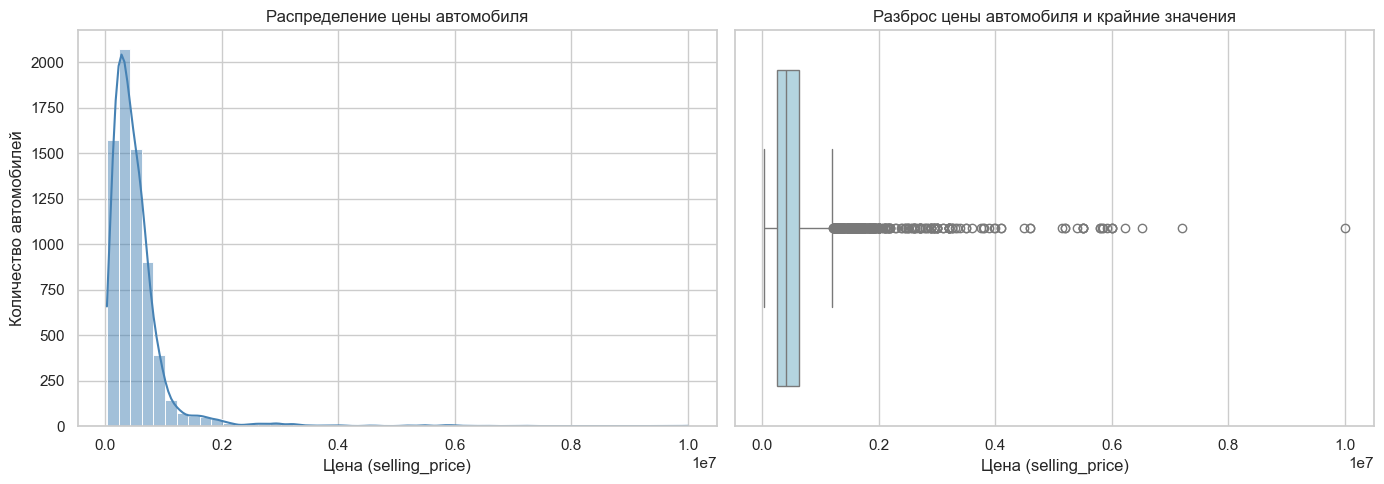

Описательные статистики целевой переменной:


,count,mean,std,min,25%,50%,75%,max
selling_price,6926.0,517270.678458,519766.985985,29999.0,250000.0,400000.0,633500.0,10000000.0


Отношение среднего к медиане: 1.29


In [54]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df["selling_price"], bins=50, kde=True, color="steelblue", ax=axes[0])
axes[0].set_title("Распределение цены автомобиля")
axes[0].set_xlabel("Цена (selling_price)")
axes[0].set_ylabel("Количество автомобилей")
sns.boxplot(x=df["selling_price"], color="lightblue", ax=axes[1])
axes[1].set_title("Разброс цены автомобиля и крайние значения")
axes[1].set_xlabel("Цена (selling_price)")
plt.tight_layout()
plt.show()

print("Описательные статистики целевой переменной:")
display(df["selling_price"].describe().to_frame().T)
print(f"Отношение среднего к медиане: {df['selling_price'].mean() / df['selling_price'].median():.2f}")

После удаления дубликатов осталось 6 926 автомобилей. Средняя цена равна примерно **517 271**, медиана — **400 000**, максимум — **10 000 000**; отношение среднего к медиане составляет **1,29**. Среднее выше медианы, а правый хвост и высокие точки на boxplot указывают на правостороннюю асимметрию. Крайние цены не удаляются автоматически: они могут соответствовать реальным дорогим автомобилям. Их влияние будет отражено в RMSE и графиках остатков.

### 3.3. Распределения числовых признаков

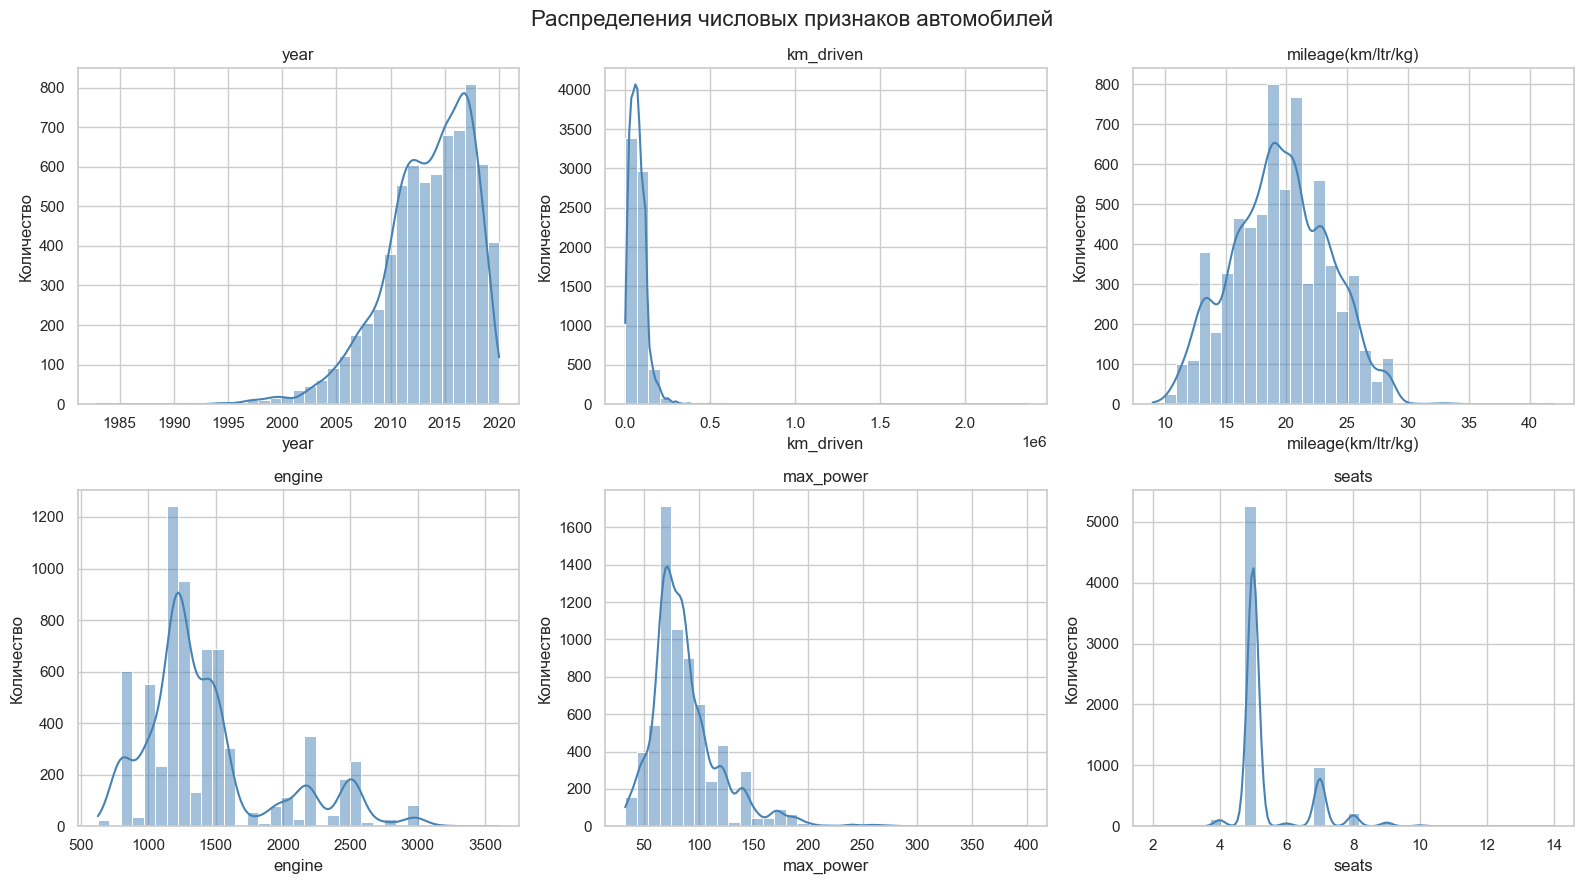

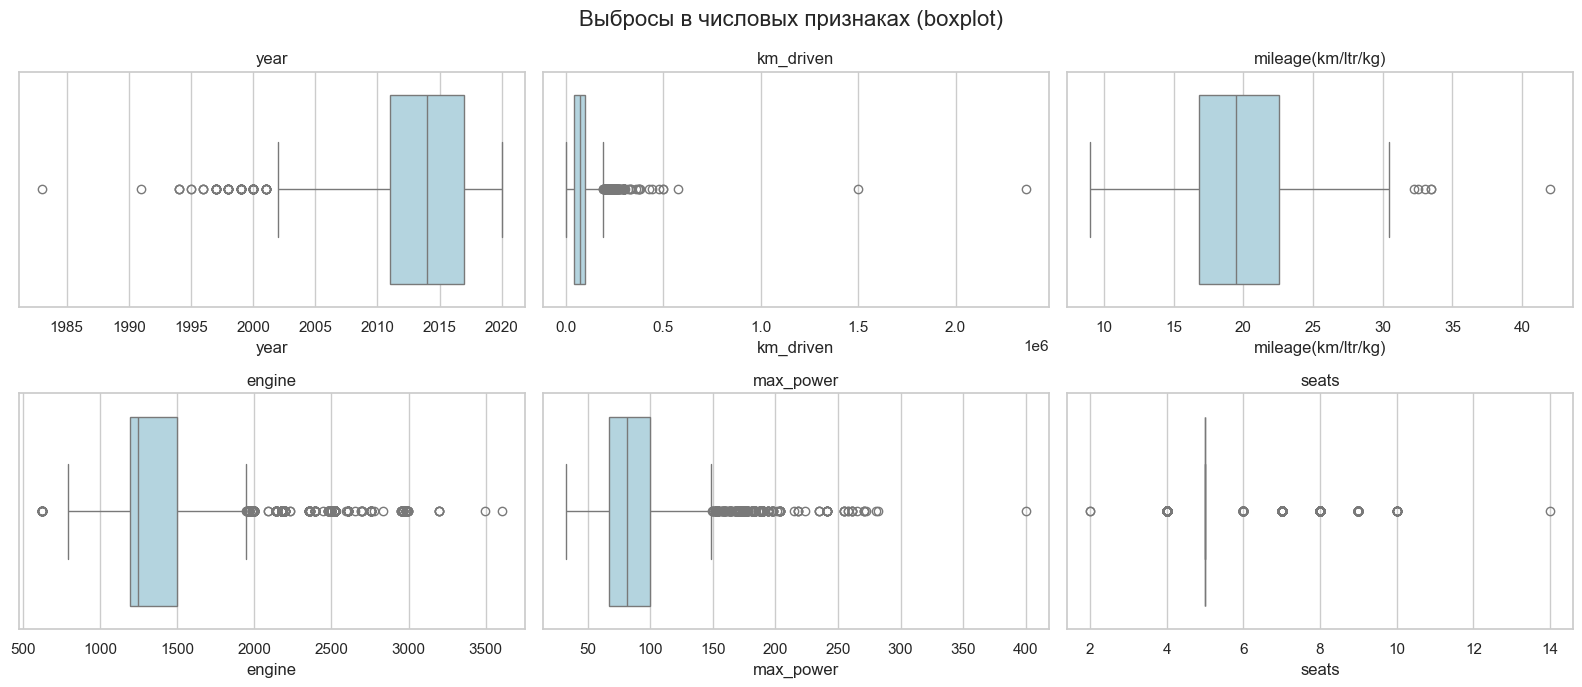

In [55]:
numeric_features = [
    "year", "km_driven", "mileage(km/ltr/kg)", "engine", "max_power", "seats"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle("Распределения числовых признаков автомобилей", fontsize=16)
for ax, col in zip(axes.flat, numeric_features):
    sns.histplot(df[col].dropna(), bins=35, kde=True, color="steelblue", ax=ax)
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Количество")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(16, 7))
fig.suptitle("Выбросы в числовых признаках (boxplot)", fontsize=16)
for ax, col in zip(axes.flat, numeric_features):
    sns.boxplot(x=df[col], color="lightblue", ax=ax)
    ax.set_title(col)
    ax.set_xlabel(col)
plt.tight_layout()
plt.show()

На графиках виден неодинаковый масштаб и форма распределения параметров. Например, пробег имеет широкий разброс, а объём двигателя и мощность могут отличаться на порядок в зависимости от модели. Boxplot показывает наблюдения за границами IQR, но это не автоматическое основание для удаления. В этой работе сохраняются крайние цены и большие пробеги: без дополнительной информации нельзя достоверно утверждать, что они являются ошибками. Некорректные неположительные значения расхода и мощности, напротив, превращены в пропуски.

### 3.4. Распределение категориальных признаков

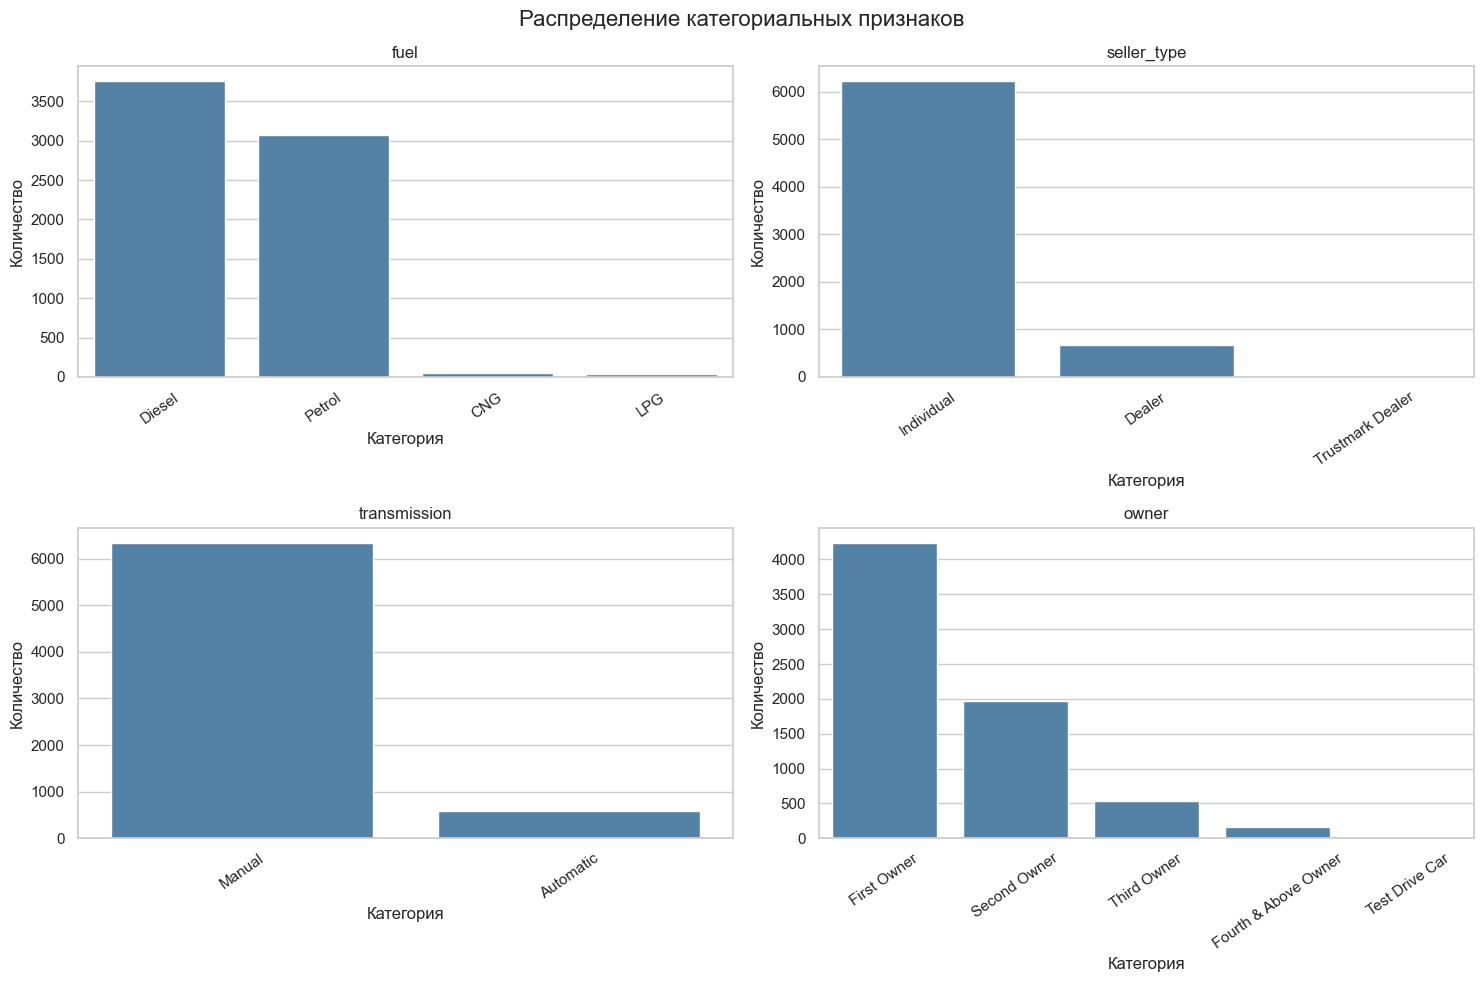

15 наиболее частых названий автомобилей:


,Количество
Модель,
Maruti Swift Dzire VDI,118
Maruti Alto 800 LXI,76
Maruti Alto LXi,69
Maruti Swift VDI,60
Maruti Swift VDI BSIV,56
Maruti Alto K10 VXI,47
Hyundai EON Era Plus,44
Maruti Wagon R VXI BS IV,43
Maruti Alto LX,43


In [56]:
categorical_features = ["name", "fuel", "seller_type", "transmission", "owner"]
plot_categories = ["fuel", "seller_type", "transmission", "owner"]
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle("Распределение категориальных признаков", fontsize=16)
for ax, col in zip(axes.flat, plot_categories):
    counts = df[col].fillna("Не указано").value_counts()
    sns.barplot(x=counts.index, y=counts.values, color="steelblue", ax=ax)
    ax.set_title(col)
    ax.set_xlabel("Категория")
    ax.set_ylabel("Количество")
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

print("15 наиболее частых названий автомобилей:")
display(df["name"].value_counts().head(15).rename_axis("Модель").to_frame("Количество"))

Категориальные графики показывают, насколько сбалансированы типы топлива, продавцов, трансмиссий и владельцев. Признак `name` содержит много уникальных моделей, поэтому его частоты показаны отдельно для 15 наиболее распространённых названий. В моделях редкие категории `name` будут объединяться параметром `min_frequency` у `OneHotEncoder`: это сокращает количество фиктивных переменных и уменьшает риск нестабильных оценок для единичных моделей.

### 3.5. Корреляционная матрица

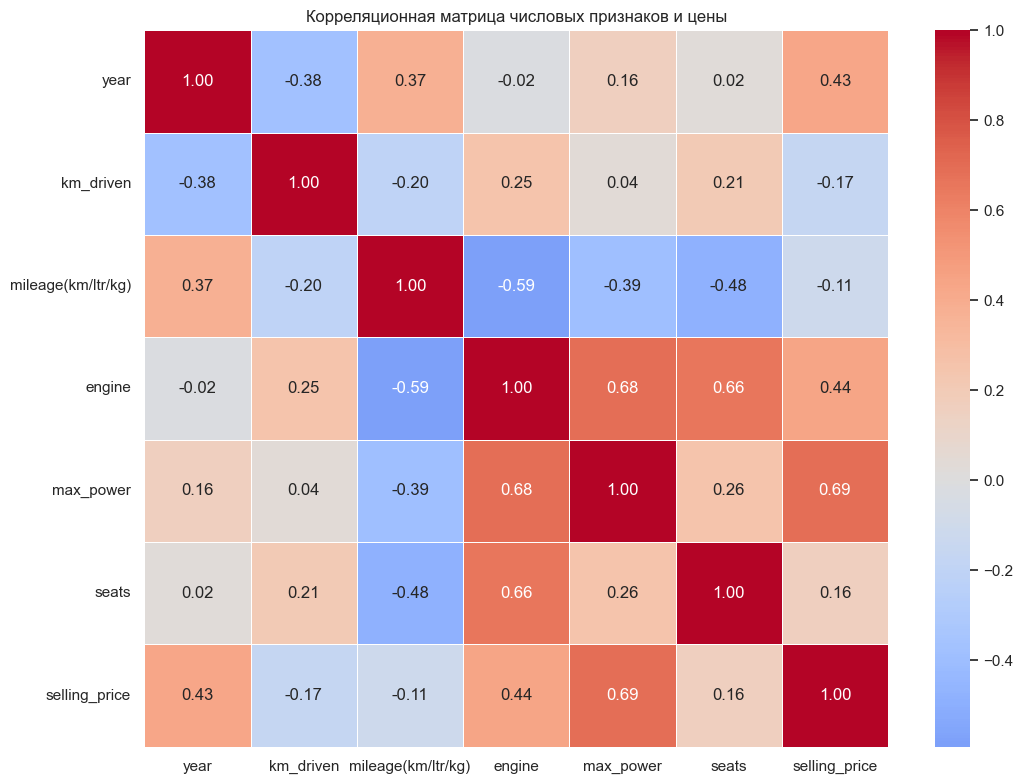

Корреляции Пирсона с целевой переменной selling_price:


,Корреляция с ценой
max_power,0.692323
engine,0.442857
year,0.433076
km_driven,-0.165620
seats,0.158111
mileage(km/ltr/kg),-0.108176


In [57]:
correlation_columns = numeric_features + ["selling_price"]
corr_matrix = df[correlation_columns].corr(method="pearson")
plt.figure(figsize=(11, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", center=0, fmt=".2f", linewidths=0.5)
plt.title("Корреляционная матрица числовых признаков и цены")
plt.tight_layout()
plt.show()

price_correlations = corr_matrix["selling_price"].drop("selling_price").sort_values(
    key=lambda values: values.abs(), ascending=False
)
print("Корреляции Пирсона с целевой переменной selling_price:")
display(price_correlations.rename("Корреляция с ценой").to_frame())

Коэффициент Пирсона отражает силу линейной связи двух числовых переменных и принимает значения от −1 до +1. В этом датасете самая высокая корреляция с ценой наблюдается у `max_power` (**r ≈ 0,692**); далее идут `engine` (**r ≈ 0,443**) и `year` (**r ≈ 0,433**). Для `km_driven` связь отрицательная и слабая (**r ≈ −0,166**), а у расхода топлива она также слабая (**r ≈ −0,108**). Корреляция показывает линейную связь по отдельности, но не доказывает причинность и не учитывает влияние остальных признаков. Для оценки взаимозависимости предикторов ниже дополнительно рассчитывается VIF.

### 3.6. Разделение на обучающую и тестовую выборки

In [58]:
target = "selling_price"
feature_columns = [col for col in df.columns if col != target]
X = df[feature_columns].copy()
y = df[target].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print(f"Полный набор после очистки: {len(df):,} наблюдений")
print(f"Обучающая выборка: {X_train.shape[0]:,} строк ({X_train.shape[0] / len(df):.1%})")
print(f"Тестовая выборка: {X_test.shape[0]:,} строк ({X_test.shape[0] / len(df):.1%})")
print(f"Числовые признаки: {numeric_features}")
print(f"Категориальные признаки: {categorical_features}")

Полный набор после очистки: 6,926 наблюдений
Обучающая выборка: 5,540 строк (80.0%)
Тестовая выборка: 1,386 строк (20.0%)
Числовые признаки: ['year', 'km_driven', 'mileage(km/ltr/kg)', 'engine', 'max_power', 'seats']
Категориальные признаки: ['name', 'fuel', 'seller_type', 'transmission', 'owner']


Данные разделены в пропорции 80/20 с фиксированным `random_state=42`. Обучающая часть используется для подбора параметров и обучения моделей, а тестовая — для итоговой оценки качества на наблюдениях, не участвовавших в подборе. Предобработка далее будет оформлена как часть `Pipeline`, поэтому медианы, категории кодировщика, стандартизация и PCA обучаются только на соответствующей обучающей части каждого фолда.

### 3.7. Оценка мультиколлинеарности с помощью VIF

In [59]:
# VIF рассчитывается по числовым предикторам обучающей части.
# Пропуски заполняются медианами, рассчитанными на X_train.
vif_imputer = SimpleImputer(strategy="median")
X_train_numeric = pd.DataFrame(
    vif_imputer.fit_transform(X_train[numeric_features]),
    columns=numeric_features,
    index=X_train.index,
)

# Константа не включается в итоговую таблицу VIF.
from statsmodels.tools.tools import add_constant
X_vif = add_constant(X_train_numeric, has_constant="add")
vif_table = pd.DataFrame({
    "Признак": X_train_numeric.columns,
    "VIF": [variance_inflation_factor(X_vif.to_numpy(), i + 1) for i in range(len(numeric_features))],
}).sort_values("VIF", ascending=False).reset_index(drop=True)
display(vif_table)

print("Условные ориентиры: VIF около 1 — слабая связь с остальными; VIF > 5 — возможная мультиколлинеарность; VIF > 10 — высокая.")

,Признак,VIF
0,engine,4.128857
1,max_power,2.386226
2,seats,2.218635
3,mileage(km/ltr/kg),2.081963
4,year,1.666318
5,km_driven,1.379919


Условные ориентиры: VIF около 1 — слабая связь с остальными; VIF > 5 — возможная мультиколлинеарность; VIF > 10 — высокая.


VIF (Variance Inflation Factor) оценивает, насколько дисперсия оценки коэффициента линейной регрессии увеличивается из-за линейной зависимости признака с другими предикторами. На обучающей части максимальный VIF получен для `engine` (**≈ 4,13**), далее идут `max_power` (**≈ 2,39**) и `seats` (**≈ 2,22**); все значения находятся ниже ориентировочного порога 5. Следовательно, среди шести числовых признаков нет выраженной мультиколлинеарности по этому правилу, хотя взаимосвязи остаются. VIF здесь оценивается только для числовых характеристик; категории с большим числом уровней не включаются в таблицу, чтобы не перегружать диагностику множеством фиктивных переменных. PCA ниже применяется к полной закодированной матрице и создаёт некоррелированные компоненты.

## 4. Ход работы: модели на исходных признаках

### 4.1. Предобработка и построение моделей

Числовые пропуски заполняются медианой, категориальные — наиболее частой категорией. Категориальные признаки кодируются методом One-Hot Encoding; неизвестные при обучении категории в тестовой выборке не вызывают ошибку. Редкие категории объединяются, если встречаются менее 15 раз в обучающем фолде. После кодирования все признаки стандартизируются: это особенно важно для Lasso и Ridge, поскольку регуляризация чувствительна к масштабу признаков.

Модели:
- **Linear Regression** — базовая линейная регрессия методом наименьших квадратов.
- **Lasso** — линейная регрессия с L1-регуляризацией, которая может занулять часть коэффициентов.
- **Ridge** — линейная регрессия с L2-регуляризацией, уменьшающей величины коэффициентов.

Параметр `alpha` для Lasso и Ridge подбирается по среднему RMSE на 5 фолдах. Финальные тестовые метрики вычисляются только после выбора параметров.

In [60]:
numeric_pipeline = SimpleImputer(strategy="median")
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=15,
        sparse_output=False,
    )),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features),
    ],
    remainder="drop",
    sparse_threshold=0.0,
    verbose_feature_names_out=False,
)

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
regressor_specs = {
    "Линейная регрессия": (LinearRegression(), [{}]),
    "Lasso": (Lasso(max_iter=20000, tol=1e-3), [
        {"regressor__alpha": [10, 100, 1000, 10000, 50000]},
    ]),
    "Ridge": (Ridge(), [
        {"regressor__alpha": [0.1, 1, 10, 100, 1000]},
    ]),
}

baseline_models = {}
baseline_rows = []
for model_name, (regressor, grid_list) in regressor_specs.items():
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("scaler", StandardScaler()),
        ("regressor", clone(regressor)),
    ])
    # Словарь параметров нужен GridSearchCV; для базовой модели сетка содержит один пустой вариант.
    param_grid = grid_list[0]
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="neg_root_mean_squared_error",
        cv=cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False,
    )
    search.fit(X_train, y_train)
    fitted = search.best_estimator_
    baseline_models[model_name] = fitted

    pred = fitted.predict(X_test)
    baseline_rows.append({
        "Модель": model_name,
        "Лучшие параметры": search.best_params_ if search.best_params_ else "параметры по умолчанию",
        "CV RMSE": -search.best_score_,
        "Test RMSE": float(np.sqrt(mean_squared_error(y_test, pred))),
        "Test R²": float(r2_score(y_test, pred)),
        "Test MAPE, %": float(mean_absolute_percentage_error(y_test, pred) * 100),
    })

baseline_results = pd.DataFrame(baseline_rows).set_index("Модель")
print("Результаты моделей на исходных признаках:")
display(baseline_results.style.format({
    "CV RMSE": "{:,.2f}", "Test RMSE": "{:,.2f}", "Test R²": "{:.4f}", "Test MAPE, %": "{:.2f}%"
}))

Результаты моделей на исходных признаках:


,Лучшие параметры,CV RMSE,Test RMSE,Test R²,"Test MAPE, %"
Модель,,,,,
Линейная регрессия,параметры по умолчанию,"308,741.64","305,815.43",0.5736,53.97%
Lasso,{'regressor__alpha': 100},"308,843.07","305,640.79",0.5741,53.90%
Ridge,{'regressor__alpha': 100},"308,423.86","305,616.45",0.5741,53.14%


На исходных признаках лучший результат по трём тестовым метрикам показывает **Ridge**: CV RMSE ≈ **308 424**, Test RMSE ≈ **305 616**, Test R² ≈ **0,5741**, Test MAPE ≈ **53,14 %**. Линейная регрессия и Lasso дают близкий результат, то есть регуляризация здесь меняет метрики незначительно. RMSE измеряется в единицах цены; R² около 0,57 означает, что модель объясняет примерно 57 % вариации цены на тестовой части. MAPE около 53 % показывает, что относительная ошибка остаётся существенной. Все значения получены по очищенной выборке, а не из примера ноутбука.

### 4.2. Графики остатков

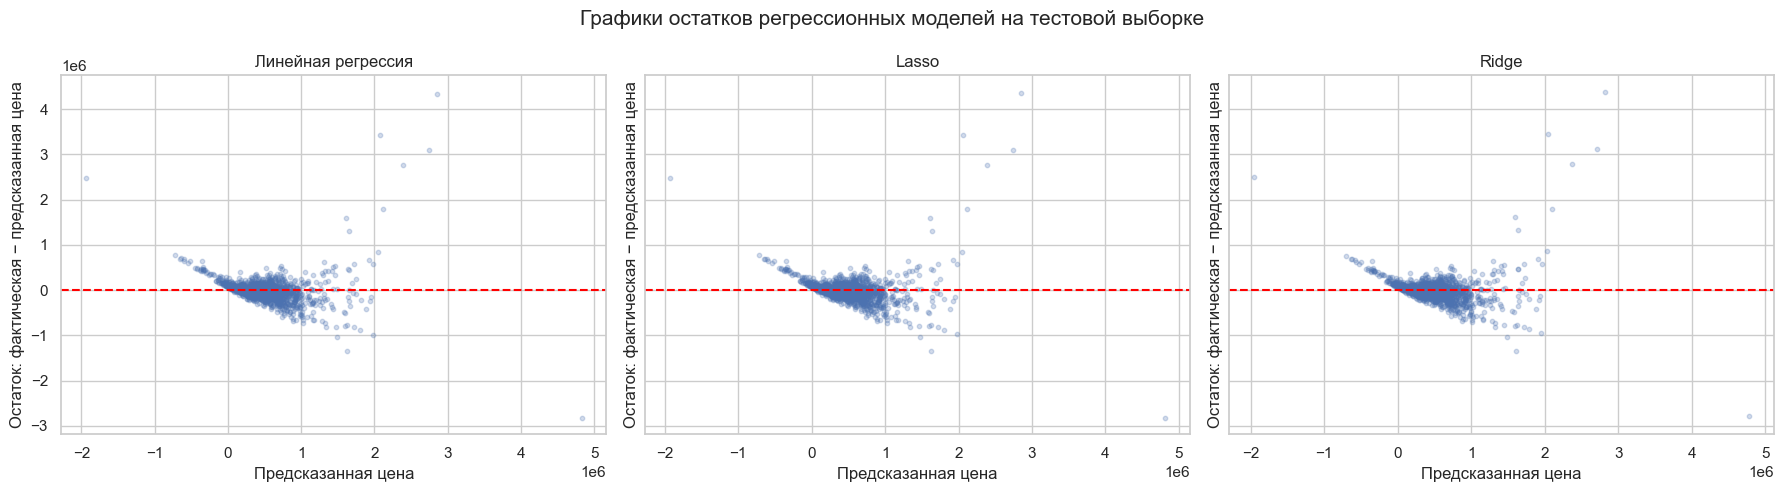

In [61]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, (model_name, fitted_model) in zip(axes, baseline_models.items()):
    predictions = fitted_model.predict(X_test)
    residuals = y_test.to_numpy() - predictions
    ax.scatter(predictions, residuals, s=10, alpha=0.25)
    ax.axhline(0, color="red", linestyle="--", linewidth=1.5)
    ax.set_title(model_name)
    ax.set_xlabel("Предсказанная цена")
    ax.set_ylabel("Остаток: фактическая − предсказанная цена")
plt.suptitle("Графики остатков регрессионных моделей на тестовой выборке", fontsize=15)
plt.tight_layout()
plt.show()

На всех трёх графиках заметна неслучайная структура: разброс остатков меняется в зависимости от предсказанной цены, а на некоторых участках формируется дугообразная граница. Это указывает на вероятную гетероскедастичность и то, что линейная зависимость описывает данные не полностью. Есть отдельные очень большие остатки у дорогих автомобилей; несколько предсказаний линейной модели находятся ниже нуля, что физически невозможно для цены и показывает ограничение регрессии на исходной шкале. Lasso и Ridge визуально очень близки к базовой модели.

## 5. Устранение мультиколлинеарности и снижение размерности с помощью PCA

PCA преобразует исходные признаки в линейные комбинации — главные компоненты, которые ортогональны друг другу. Перед PCA все преобразованные признаки стандартизируются. Сначала построим график каменистой осыпи и определим минимальное число компонент, объясняющих не менее 95 % дисперсии. Затем модели будут обучены на компонентах. Все этапы PCA также включены в конвейер кросс-валидации, чтобы информация из валидационных фолдов не использовалась при обучении преобразования.

### 5.1. Стандартизация и график каменистой осыпи

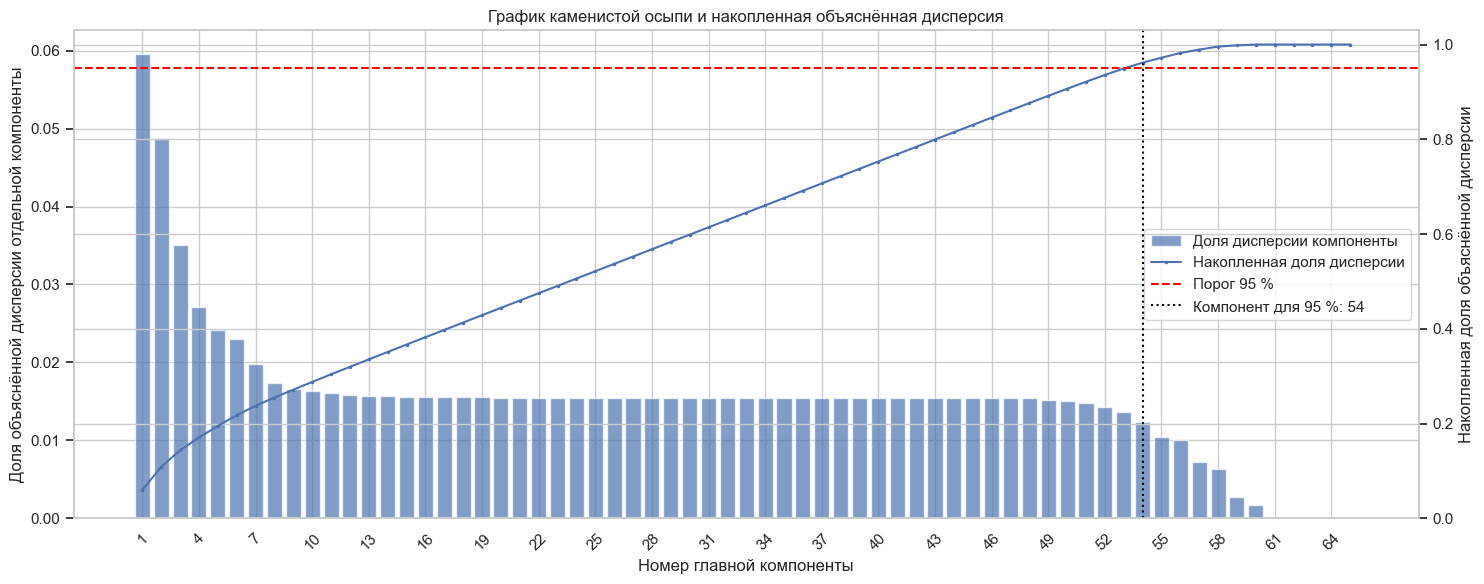

Число признаков после кодирования: 65
Компонент для объяснения не менее 95 % дисперсии: 54
Накопленная доля дисперсии для 54 компонент: 0.9618


In [62]:
# Подгоняем преобразования только на тренировочной выборке.
pca_preprocessor = clone(preprocessor)
X_train_encoded = pca_preprocessor.fit_transform(X_train)
feature_scaler_for_pca = StandardScaler()
X_train_scaled_for_pca = feature_scaler_for_pca.fit_transform(X_train_encoded)

pca_full = PCA(svd_solver="full")
pca_full.fit(X_train_scaled_for_pca)
explained = pca_full.explained_variance_ratio_
cumulative_explained = np.cumsum(explained)
n_components_95 = int(np.searchsorted(cumulative_explained, 0.95) + 1)

component_numbers = np.arange(1, len(explained) + 1)
fig, ax1 = plt.subplots(figsize=(15, 6))
ax1.bar(component_numbers, explained, alpha=0.7, label="Доля дисперсии компоненты")
ax1.set_xlabel("Номер главной компоненты")
ax1.set_ylabel("Доля объяснённой дисперсии отдельной компоненты")
ax1.set_title("График каменистой осыпи и накопленная объяснённая дисперсия")
ax1.set_xticks(component_numbers[::max(1, len(component_numbers)//20)])
ax1.tick_params(axis="x", rotation=45)

ax2 = ax1.twinx()
ax2.plot(component_numbers, cumulative_explained, marker=".", markersize=3, linewidth=1.5,
         label="Накопленная доля дисперсии")
ax2.axhline(0.95, color="red", linestyle="--", label="Порог 95 %")
ax2.axvline(n_components_95, color="black", linestyle=":",
            label=f"Компонент для 95 %: {n_components_95}")
ax2.set_ylabel("Накопленная доля объяснённой дисперсии")
ax2.set_ylim(0, 1.03)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="center right")
plt.tight_layout()
plt.show()

print(f"Число признаков после кодирования: {X_train_scaled_for_pca.shape[1]}")
print(f"Компонент для объяснения не менее 95 % дисперсии: {n_components_95}")
print(f"Накопленная доля дисперсии для {n_components_95} компонент: {cumulative_explained[n_components_95-1]:.4f}")

После One-Hot Encoding получено **65 признаков**. Чтобы сохранить не менее 95 % дисперсии на обучающей части, достаточно **54 главных компонент**; фактически они объясняют около **96,18 %** дисперсии. Таким образом, размерность уменьшена на 11 столбцов (примерно на 16,9 %). Главные компоненты ортогональны друг другу и не имеют линейной корреляции в обучающей выборке. При этом часть информации, полезной именно для прогноза цены, может быть потеряна: PCA максимизирует дисперсию признаков, а не зависимость с целевой переменной.

### 5.2. Обучение моделей на главных компонентах

In [63]:
def make_pca_pipeline(regressor):
    return Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=0.95, svd_solver="full")),
        ("regressor", clone(regressor)),
    ])

pca_models = {}
pca_rows = []
for model_name, (regressor, grid_list) in regressor_specs.items():
    pipeline = make_pca_pipeline(regressor)
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=grid_list[0],
        scoring="neg_root_mean_squared_error",
        cv=cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False,
    )
    search.fit(X_train, y_train)
    fitted = search.best_estimator_
    pca_models[model_name] = fitted

    pred = fitted.predict(X_test)
    pca_rows.append({
        "Модель": model_name,
        "Лучшие параметры": search.best_params_ if search.best_params_ else "параметры по умолчанию",
        "CV RMSE": -search.best_score_,
        "Test RMSE": float(np.sqrt(mean_squared_error(y_test, pred))),
        "Test R²": float(r2_score(y_test, pred)),
        "Test MAPE, %": float(mean_absolute_percentage_error(y_test, pred) * 100),
        "Число компонент": int(fitted.named_steps["pca"].n_components_),
    })

pca_results = pd.DataFrame(pca_rows).set_index("Модель")
print("Результаты моделей после PCA:")
display(pca_results.style.format({
    "CV RMSE": "{:,.2f}", "Test RMSE": "{:,.2f}", "Test R²": "{:.4f}", "Test MAPE, %": "{:.2f}%"
}))

Результаты моделей после PCA:


,Лучшие параметры,CV RMSE,Test RMSE,Test R²,"Test MAPE, %",Число компонент
Модель,,,,,,
Линейная регрессия,параметры по умолчанию,"348,602.74","352,712.57",0.4328,57.88%,54
Lasso,{'regressor__alpha': 1000},"348,561.24","351,847.47",0.4355,57.82%,54
Ridge,{'regressor__alpha': 100},"348,514.39","352,056.45",0.4349,57.66%,54


После PCA лучший результат по RMSE и R² показывает Lasso: Test RMSE ≈ **351 847**, Test R² ≈ **0,4355**, MAPE ≈ **57,82 %**. По MAPE минимальное значение у Ridge — около **57,66 %**, но его RMSE немного выше. В целом показатели моделей с PCA хуже результатов на исходных признаках. В PCA-конвейере порядок операций следующий: заполнение пропусков и One-Hot Encoding → стандартизация → PCA, сохраняющий 95 % дисперсии → регрессор. `GridSearchCV` заново обучает предобработку, стандартизацию и PCA внутри каждого обучающего фолда, поэтому тестовые данные не участвуют ни в выборе компонент, ни в настройке регуляризации.

### 5.3. Остатки моделей после PCA

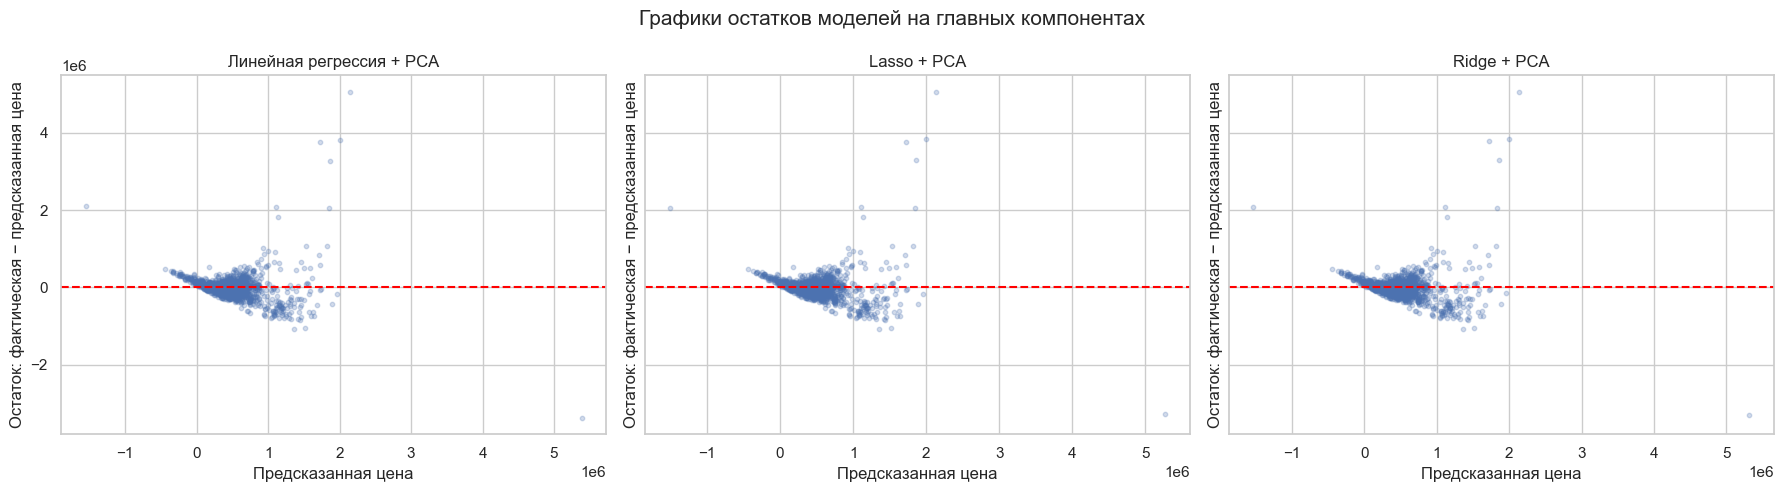

In [64]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, (model_name, fitted_model) in zip(axes, pca_models.items()):
    predictions = fitted_model.predict(X_test)
    residuals = y_test.to_numpy() - predictions
    ax.scatter(predictions, residuals, s=10, alpha=0.25)
    ax.axhline(0, color="red", linestyle="--", linewidth=1.5)
    ax.set_title(f"{model_name} + PCA")
    ax.set_xlabel("Предсказанная цена")
    ax.set_ylabel("Остаток: фактическая − предсказанная цена")
plt.suptitle("Графики остатков моделей на главных компонентах", fontsize=15)
plt.tight_layout()
plt.show()

Графики остатков после PCA читаются так же, как для исходных признаков. Если сохраняется веерообразная форма или сильные отклонения на верхнем диапазоне цены, значит, ортогональное преобразование признаков не устранило неравномерность ошибок и возможную нелинейность зависимости. PCA устраняет линейную корреляцию между компонентами, но не гарантирует гомоскедастичность и не превращает линейную модель в нелинейную.

## 6. Сравнение результатов до и после PCA

Сравнение всех шести вариантов:


,Представление признаков,Модель,CV RMSE,Test RMSE,Test R²,"Test MAPE, %"
0,Исходные признаки,Линейная регрессия,"308,741.64","305,815.43",0.5736,53.97%
1,Исходные признаки,Lasso,"308,843.07","305,640.79",0.5741,53.90%
2,Исходные признаки,Ridge,"308,423.86","305,616.45",0.5741,53.14%
3,Главные компоненты PCA,Линейная регрессия,"348,602.74","352,712.57",0.4328,57.88%
4,Главные компоненты PCA,Lasso,"348,561.24","351,847.47",0.4355,57.82%
5,Главные компоненты PCA,Ridge,"348,514.39","352,056.45",0.4349,57.66%


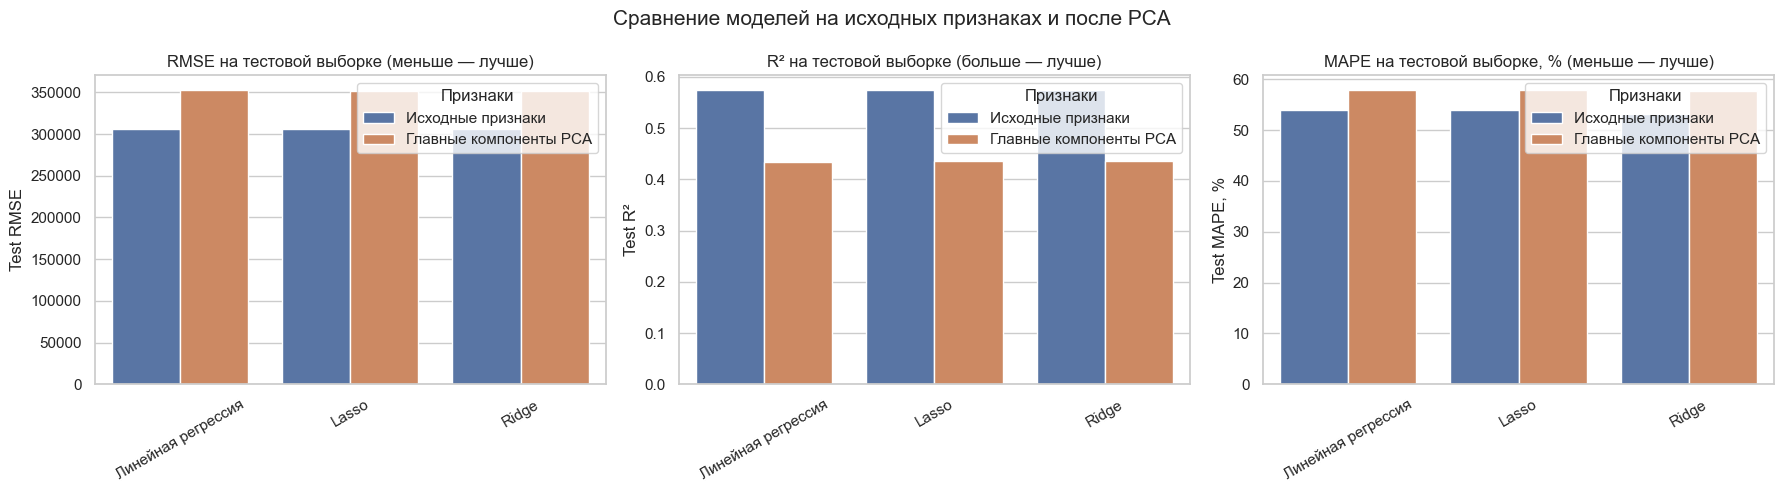

Лучший вариант по Test RMSE: Исходные признаки — Ridge
Лучший вариант по Test R²: Исходные признаки — Ridge
Лучший вариант по Test MAPE: Исходные признаки — Ridge


In [65]:
comparison_rows = []
for representation, results in [("Исходные признаки", baseline_results), ("Главные компоненты PCA", pca_results)]:
    for model_name, row in results.iterrows():
        comparison_rows.append({
            "Представление признаков": representation,
            "Модель": model_name,
            "CV RMSE": row["CV RMSE"],
            "Test RMSE": row["Test RMSE"],
            "Test R²": row["Test R²"],
            "Test MAPE, %": row["Test MAPE, %"],
        })
comparison = pd.DataFrame(comparison_rows)
print("Сравнение всех шести вариантов:")
display(comparison.style.format({
    "CV RMSE": "{:,.2f}", "Test RMSE": "{:,.2f}", "Test R²": "{:.4f}", "Test MAPE, %": "{:.2f}%"
}))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
metrics_to_plot = [
    ("Test RMSE", "RMSE на тестовой выборке (меньше — лучше)"),
    ("Test R²", "R² на тестовой выборке (больше — лучше)"),
    ("Test MAPE, %", "MAPE на тестовой выборке, % (меньше — лучше)"),
]
for ax, (metric, title) in zip(axes, metrics_to_plot):
    sns.barplot(data=comparison, x="Модель", y=metric, hue="Представление признаков", ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(title="Признаки")
plt.suptitle("Сравнение моделей на исходных признаках и после PCA", fontsize=15)
plt.tight_layout()
plt.show()

best_rmse_row = comparison.loc[comparison["Test RMSE"].idxmin()]
best_r2_row = comparison.loc[comparison["Test R²"].idxmax()]
best_mape_row = comparison.loc[comparison["Test MAPE, %"].idxmin()]
print("Лучший вариант по Test RMSE:", best_rmse_row["Представление признаков"], "—", best_rmse_row["Модель"])
print("Лучший вариант по Test R²:", best_r2_row["Представление признаков"], "—", best_r2_row["Модель"])
print("Лучший вариант по Test MAPE:", best_mape_row["Представление признаков"], "—", best_mape_row["Модель"])

Сравнение показывает, что лучшая модель на исходных признаках — Ridge (Test RMSE ≈ **305 616**, R² ≈ **0,5741**, MAPE ≈ **53,14 %**). Для Ridge после PCA RMSE увеличился до ≈ **352 056** — примерно на **15,2 %**; R² снизился до ≈ **0,4349**, а MAPE вырос до ≈ **57,66 %**. Лучший по RMSE вариант после PCA (Lasso) также уступает лучшему исходному варианту. В данном эксперименте PCA позволил уменьшить число признаков с 65 до 54 и сделать компоненты некоррелированными, но цена за такое сокращение — потеря качества прогнозирования. Причина может заключаться в том, что PCA выбирает компоненты по дисперсии признаков, а не по их предсказательной ценности для цены автомобиля.

## 7. Заключение

В работе исследован датасет `cardekho.csv` с характеристиками подержанных автомобилей. Целевой признак `selling_price` является количественным, поэтому была решена задача регрессии. В первичном анализе проверены типы данных, пропуски, дубликаты, распределения числовых и категориальных признаков, а также корреляции между числовыми параметрами.

На этапе подготовки `max_power` преобразован в числовой тип, полные дубликаты удалены, некорректные неположительные значения расхода и мощности заменены пропусками. Пропуски заполняются внутри конвейеров, а категориальные признаки преобразуются One-Hot Encoding. Для уменьшения влияния масштаба признаки стандартизируются.

Построены Linear Regression, Lasso и Ridge. Их качество оценено кросс-валидацией и на отдельной тестовой выборке по RMSE, R² и MAPE. Графики остатков помогают диагностировать систематические ошибки и возможную гетероскедастичность. Затем стандартизированные признаки преобразованы с помощью PCA; модели обучены повторно и сравнены с исходными вариантами.

Лучший результат на исходных признаках показала **Ridge**: Test RMSE ≈ 305 616, R² ≈ 0,5741 и MAPE ≈ 53,14 %. После PCA лучшей по RMSE оказалась Lasso (≈ 351 847), однако её ошибка выше, а R² ниже. Для Ridge PCA увеличил RMSE примерно на 15,2 % и MAPE примерно на 4,52 процентного пункта. VIF числовых предикторов не превысил 5 (максимум около 4,13), поэтому выраженная мультиколлинеарность именно среди числовых переменных не выявлена; PCA применялся к полной закодированной матрице для получения более компактного некоррелированного представления. В этом эксперименте снижение размерности не улучшило прогнозирование. Ошибка остаётся заметной, остатки демонстрируют структуру и неодинаковый разброс, что указывает на ограничения линейной модели и возможную гетероскедастичность. В качестве дальнейшего развития можно сравнить модель с логарифмированием цены или нелинейные алгоритмы, но это выходит за рамки текущей постановки.

## 8. Список источников

1. Kaggle. **Vehicle Dataset from CarDekho** [Электронный ресурс]. URL: https://www.kaggle.com/datasets/nehalbirla/vehicle-dataset-from-cardekho (дата обращения: 15.10.2026). Название и состав датасета использованы для ориентации; анализ и численные результаты рассчитаны по приложенному `cardekho.csv`.
2. scikit-learn. **LinearRegression** [Электронный ресурс]. URL: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html (дата обращения: 15.10.2026).
3. scikit-learn. **Lasso** [Электронный ресурс]. URL: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html (дата обращения: 15.10.2026).
4. scikit-learn. **Ridge** [Электронный ресурс]. URL: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html (дата обращения: 15.10.2026).
5. scikit-learn. **PCA** [Электронный ресурс]. URL: https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html (дата обращения: 15.10.2026).
6. scikit-learn. **Model evaluation: quantifying the quality of predictions** [Электронный ресурс]. URL: https://scikit-learn.org/stable/modules/model_evaluation.html (дата обращения: 15.10.2026).
7. statsmodels. **variance_inflation_factor** [Электронный ресурс]. URL: https://www.statsmodels.org/stable/generated/statsmodels.stats.outliers_influence.variance_inflation_factor.html (дата обращения: 15.10.2026).